# BÁO CÁO KHOA HỌC DỮ LIỆU & HỌC MÁY TOÀN DIỆN (END-TO-END PIPELINE)
## Đề Tài: Phân Loại Mức Độ Hiệu Suất Học Tập Dựa Trên Dữ Liệu Hành Vi Số Của Sinh Viên
### (Student Productivity and Digital Distraction Analysis)

---

### TỔNG QUAN DỰ ÁN
Trong thời đại chuyển đổi số, sinh viên đại học thường xuyên tương tác với nhiều thiết bị công nghệ (smartphone, laptop, tablet). Sự bùng nổ của mạng xã hội, ứng dụng giải trí và thông báo liên tục gây ra tình trạng **xao nhãng số (digital distraction)**, ảnh hưởng trực tiếp đến chu kỳ giấc ngủ, mức độ căng thẳng, thời lượng tự học và kết quả học tập tích lũy (GPA).

Dự án này triển khai một **Pipeline Khoa học Dữ liệu & Học máy hoàn chỉnh từ A đến Z** tuân thủ nghiêm ngặt các tiêu chuẩn học thuật và kỹ thuật:
1. **Tiền xử lý dữ liệu (Section 2.1):** Kiểm tra cấu trúc, xử lý giá trị khuyết thiếu (Imputation), chuẩn đoán ngoại lai (Outliers IQR & Z-score), mã hóa thứ bậc/định danh (Ordinal & One-Hot Encoding), chuẩn hóa (`StandardScaler`), và rời rạc hóa biến mục tiêu.
2. **Phân tích & Giảm chiều dữ liệu (Section 2.2):** Khám phá EDA, ma trận tương quan Heatmap, phân rã trị riêng (Eigenvalues), so sánh chuyên sâu 02 phương pháp giảm chiều (**PCA** vs **TruncatedSVD**), phân tích trọng số Loadings và trực quan hóa đa chiều (Pairwise Grid, 2D/3D Scatter).
3. **Phân cụm không giám sát (Section 2.3):** Tìm kiếm $K$ tối ưu (Elbow, Silhouette, BIC/AIC), áp dụng **K-Means**, **GMM (EM)**, và **DBSCAN**, đánh giá bằng hệ chỉ số nội tại (Internal) và ngoại tại (External ARI, NMI, Purity), lập bảng Cross-tabulation, trực quan hóa đồng thời Cụm (Màu) và Nhãn thực tế (Shape marker).
4. **Phân loại có giám sát & Chuyển đổi Hồi quy (Section 2.4):**
   - Đánh giá ma trận thực nghiệm 3 nhóm mô hình (Sinh vs Phân biệt, Tuyến tính vs Phi tuyến) qua 3 tỷ lệ chia (80:20, 70:30, 60:40) và 2 không gian dữ liệu (Gốc vs PCA).
   - Chuẩn đoán chuyên sâu hiện tượng **Overfitting** và đánh giá hiệu quả của các kỹ thuật **Regularization**.
   - Trực quan hóa Ma trận nhầm lẫn chuẩn hóa, đường cong Multiclass ROC/PR và phân tích ca dự đoán sai.
   - Chuyển đổi sang bài toán hồi quy thông qua hàm quyết định (Decision Function) của lớp mục tiêu, so sánh mô hình hồi quy trên không gian đầy đủ $D$ chiều vs không gian giảm còn $\lfloor D/3 \rfloor$ chiều để lý giải sự suy giảm hiệu năng theo lý thuyết phương sai bảo tồn.

In [1]:
# 1. Cài đặt môi trường & Import thư viện
import os
import sys

# Ensure project root is in sys.path and set working directory to project root
current_dir = os.path.abspath('')
project_root = os.path.dirname(current_dir) if os.path.basename(current_dir) == 'notebooks' else current_dir
if project_root not in sys.path:
    sys.path.insert(0, project_root)
os.chdir(project_root)

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import warnings
warnings.filterwarnings('ignore')

# Matplotlib visual styling
plt.style.use('seaborn-v0_8-whitegrid' if 'seaborn-v0_8-whitegrid' in plt.style.available else 'default')
plt.rcParams['font.sans-serif'] = 'DejaVu Sans'
plt.rcParams['figure.dpi'] = 120

print(f"[OK] Numpy: {np.__version__} | Pandas: {pd.__version__}")


[OK] Numpy: 2.5.4 | Pandas: 3.0.6


---
# PHẦN 2.1: TIỀN XỬ LÝ DỮ LIỆU (DATA PREPROCESSING)

### Cơ sở lý thuyết:
- **Xử lý Missing Data:** Giá trị khuyết thiếu được phân loại theo MCAR (Missing Completely at Random), MAR hoặc MNAR. Với biến số, phương vị (median) được áp dụng để tránh nhạy cảm với ngoại lai; với biến định tính, yếu vị (mode) được sử dụng.
- **Phát hiện Ngoại lai (Outliers):**
  - Tiêu chuẩn IQR (Interquartile Range): $[Q_1 - 1.5 \times IQR, Q_3 + 1.5 \times IQR]$ với $IQR = Q_3 - Q_1$.
  - Tiêu chuẩn $Z$-score: $Z = \frac{x - \mu}{\sigma}$, mẫu có $|Z| > 3$ được xem xét điều chỉnh (Winsorization/Capping).
- **Mã hóa (Encoding):**
  - Biến thứ bậc (Ordinal): Sử dụng `OrdinalEncoder` bảo toàn mối quan hệ thứ tự tự nhiên (ví dụ: Freshman < Sophomore < Junior < Senior).
  - Biến định danh (Nominal): Sử dụng `OneHotEncoder` mở rộng không gian đặc trưng thành các vector nhị phân độc lập.
- **Rời rạc hóa (Target Discretization):** Điểm hiệu suất $Productivity\_Score$ được phân vị thành 3 lớp: `Low` (Thấp), `Medium` (Trung bình), `High` (Cao).
- **Chuẩn hóa (Standardization):** $z = \frac{x - \mu}{\sigma}$ đưa tất cả biến số về phân phối có trung bình bằng 0 và phương sai bằng 1.

In [2]:
# Thực thi module tiền xử lý dữ liệu Step 1
from src.step1_preprocessing import run_preprocessing

df_processed = run_preprocessing()
print(f"Dữ liệu sau khi tiền xử lý hoàn tất có kích thước: {df_processed.shape}")


[STEP 1] Reading raw dataset...
Loaded 3500 rows, 21 columns.
Missing values found in 5 columns.
  Imputed Study_Hours_Per_Day with median: 4.21
  Imputed Sleep_Duration_Hours with median: 6.23
  Imputed Attendance_Rate_Percentage with median: 82.13
  Imputed Major_Category with mode: STEM
  Imputed Stress_Level with mode: High
Target Discretization Thresholds: Low <= 85.20 < Medium <= 94.95 < High
Feature Dimension Before OHE: 20 -> After OHE: 35


[SUCCESS] Step 1 Preprocessing completed. Processed file saved to 'D:\Duan\ML_PLoai_SinhVien_SuDungThietBiSo\data\processed\student_data_processed.csv'
Dữ liệu sau khi tiền xử lý hoàn tất có kích thước: (3500, 37)


In [3]:
# Hiển thị từ điển dữ liệu (Data Dictionary)
dict_df = pd.read_csv('reports/metrics/01_data_dictionary.csv')
dict_df


,Column,Type,Meaning
0,Student_ID,Identifier,Mã định danh duy nhất của sinh viên
1,Age,Numerical (Discrete),Độ tuổi sinh viên (18 - 28 tuổi)
2,Gender,Categorical (Nominal),"Giới tính (Female, Male, Non-Binary)"
3,Academic_Level,Categorical (Ordinal),Năm học đại học / sau đại học
4,Major_Category,Categorical (Nominal),"Khối ngành học (STEM, Business, Humanities,...)"
5,Daily_Screen_Time_Hours,Numerical (Continuous),Tổng thời gian dùng màn hình số hàng ngày (giờ)
6,Study_Hours_Per_Day,Numerical (Continuous),Thời gian tự học trung bình mỗi ngày (giờ)
7,Social_Media_Hours,Numerical (Continuous),Thời gian dùng mạng xã hội (giờ/ngày)
8,Gaming_Hours,Numerical (Continuous),Thời gian chơi game (giờ/ngày)
9,Phone_Unlocks_Per_Day,Numerical (Discrete),Số lần mở khóa điện thoại trong ngày


In [4]:
# Bảng tổng kết xử lý giá trị ngoại lai (Outliers Capping Summary)
outlier_df = pd.read_csv('reports/metrics/01_outlier_summary.csv')
outlier_df.head(10)


,Feature,Q1,Q3,IQR,Lower_Bound_IQR,Upper_Bound_IQR,Outliers_IQR_Count,Outliers_Zscore_Count
0,Age,19.00,21.00,2.00,16.00,24.00,97,71
1,Daily_Screen_Time_Hours,8.37,10.66,2.29,4.93,14.10,33,11
2,Study_Hours_Per_Day,3.40,4.99,1.59,1.01,7.38,17,7
3,Social_Media_Hours,1.89,3.66,1.77,-0.77,6.32,27,13
4,Gaming_Hours,0.36,1.69,1.33,-1.64,3.68,164,50
5,Phone_Unlocks_Per_Day,106.00,134.25,28.25,63.62,176.62,21,8
6,Notification_Count_Daily,154.00,199.00,45.00,86.50,266.50,23,7
7,Sleep_Duration_Hours,5.71,6.75,1.04,4.14,8.31,19,9
8,Physical_Activity_Minutes,36.00,64.00,28.00,-6.00,106.00,155,72
9,Attendance_Rate_Percentage,78.43,86.17,7.74,66.81,97.79,22,9


In [5]:
# Phân phối tần số của biến mục tiêu sau khi rời rạc hóa (Target Distribution)
target_dist = pd.read_csv('reports/metrics/01_target_distribution.csv')
print("Phân phối 3 lớp mục tiêu:")
print(target_dist)

# So sánh số chiều trước và sau khi One-Hot Encoding
import json
with open('reports/metrics/01_preprocessing_metadata.json', 'r', encoding='utf-8') as f:
    dim_meta = json.load(f)
print(f"\nTổng số bản ghi: {dim_meta['Total_Samples']}")
print(f"Số thuộc tính trước One-Hot Encoding: {dim_meta['Input_Features_Before_OHE']}")
print(f"Số thuộc tính sau One-Hot Encoding: {dim_meta['Input_Features_After_OHE']}")


Phân phối 3 lớp mục tiêu:
  Productivity_Class  Count  Percentage
0                Low   1168       33.37
1             Medium   1166       33.31
2               High   1166       33.31

Tổng số bản ghi: 3500
Số thuộc tính trước One-Hot Encoding: 20
Số thuộc tính sau One-Hot Encoding: 35


---
# PHẦN 2.2: PHÂN TÍCH VÀ TRỰC QUAN HÓA DỮ LIỆU (EDA & DIMENSIONALITY REDUCTION)

### Cơ sở lý thuyết:
1. **Phân tích thành phần chính (PCA):**
   - Tìm kiếm phép biến đổi trực giao tọa độ $Y = X W$ sao cho phương sai trên từng trục mới là cực đại.
   - Trị riêng $\lambda_i$ của ma trận hiệp phương sai $\Sigma = \frac{1}{N} X^T X$ biểu thị phương sai của thành phần chính thứ $i$.
   - Tỷ lệ phương sai giải thích: $\text{EVR}_i = \frac{\lambda_i}{\sum_{j=1}^D \lambda_j}$.
   - Trọng số Loadings: $L_{ij} = W_{ij} \sqrt{\lambda_j}$ phản ánh mức độ đóng góp của biến gốc $i$ vào thành phần chính $j$.
2. **So sánh với TruncatedSVD:**
   - TruncatedSVD phân rã trực tiếp ma trận $X = U \Sigma V^T$ mà không bắt buộc dữ liệu phải trừ trung bình (Zero-mean centering), rất phù hợp với ma trận thưa. Khi dữ liệu đã được trừ trung bình, TruncatedSVD và PCA cho kết quả tương đương về mặt hình học.

In [6]:
# Thực thi module phân tích EDA & Giảm chiều dữ liệu Step 2
from src.step2_eda_dim_reduction import run_eda_dim_reduction

run_eda_dim_reduction()


[STEP 2] Loading processed dataset for EDA & Dimensionality Reduction...


Computing correlation matrix...


Generating feature-target relationship charts...


Executing Dimensionality Reduction (PCA & TruncatedSVD)...


Computing Component Loadings...


Visualizing pairwise component grid (PC1 to PC4)...


[SUCCESS] Step 2 EDA & Dim Reduction complete. PCA 90% variance uses 23 components.


### 1. Ma trận tương quan giữa các biến số chính (Pearson Correlation Heatmap)
Tương quan âm mạnh được ghi nhận giữa thời gian sử dụng màn hình (`Daily_Screen_Time_Hours`), mạng xã hội (`Social_Media_Hours`), số lần mở khóa điện thoại (`Phone_Unlocks_Per_Day`) với điểm GPA và thời gian tự học. Điều này phản ánh rõ cơ chế phân tán chú ý kỹ thuật số đối với sinh viên.

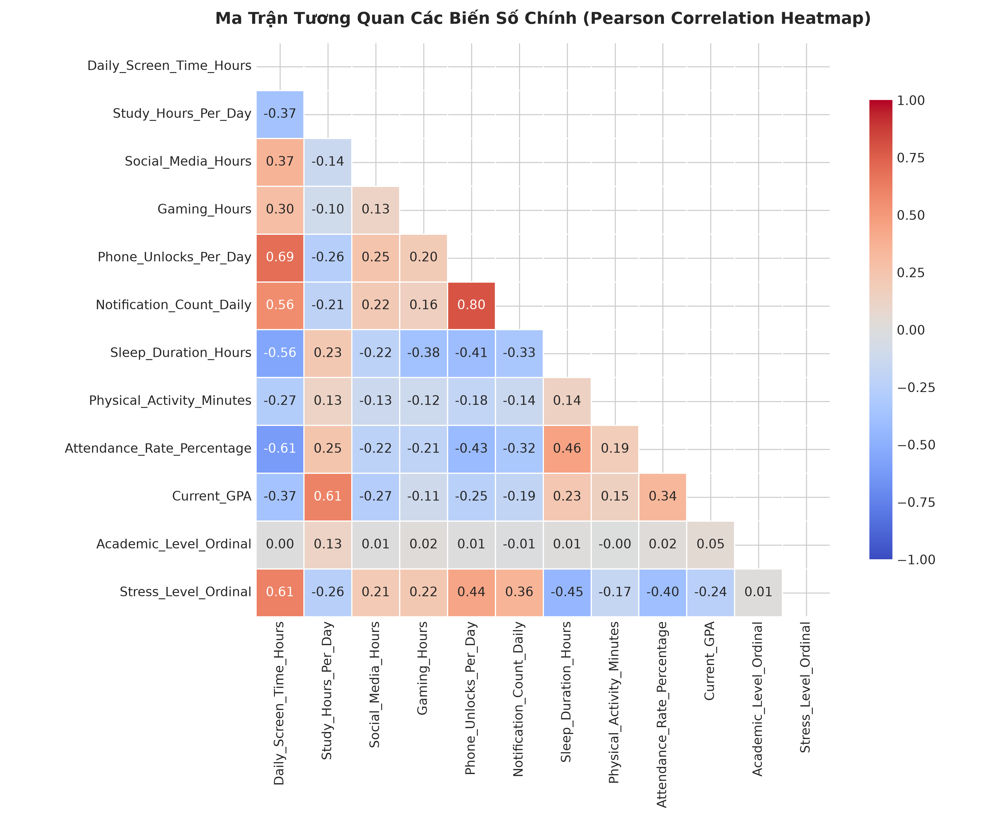

In [7]:
from IPython.display import Image, display
display(Image(filename='reports/figures/02_correlation_heatmap.png'))


### 2. Mối quan hệ giữa các biến số then chốt và nhãn phân loại (Boxplots & Violin Plots)
Các sinh viên thuộc nhóm hiệu suất cao (`High`) có thời lượng tự học trung bình và điểm GPA vượt trội, đồng thời thời gian dùng màn hình và mạng xã hội thấp hơn rõ rệt so với nhóm `Low`.

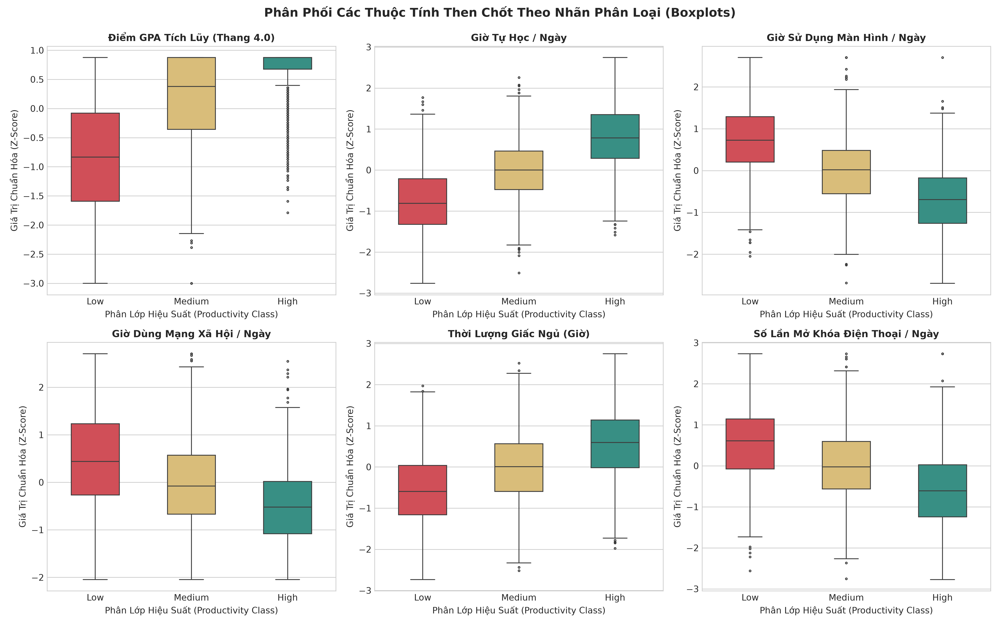

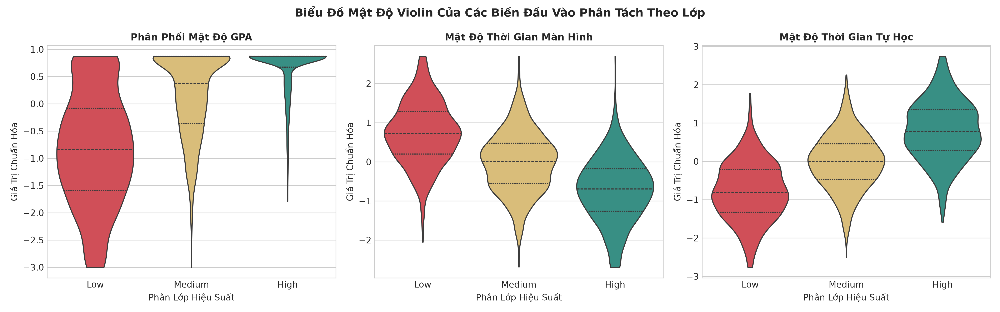

In [8]:
display(Image(filename='reports/figures/02_feature_boxplots_by_target.png'))
display(Image(filename='reports/figures/02_feature_violin_plots.png'))


### 3. Phân tích Scree Plot & Phương sai giải thích tích lũy (PCA vs TruncatedSVD)

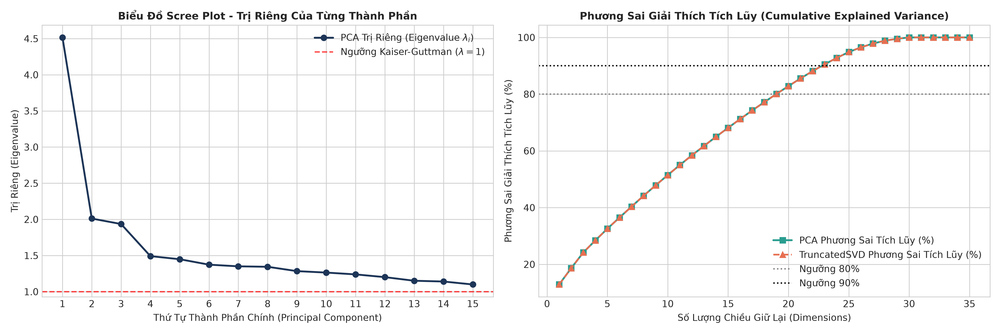

In [9]:
display(Image(filename='reports/figures/02_scree_plot_pca_svd.png'))


In [10]:
# Bảng so sánh định lượng giữa PCA và TruncatedSVD
comp_dim = pd.read_csv('reports/metrics/02_dim_reduction_comparison.csv')
comp_dim


,Tiêu Chí Đánh Giá,PCA,TruncatedSVD
0,Số thành phần đạt >= 50% phương sai,10,10
1,Số thành phần đạt >= 75% phương sai,18,18
2,Số thành phần đạt >= 85% phương sai,21,21
3,Số thành phần đạt >= 90% phương sai,23,23
4,Số thành phần đạt >= 95% phương sai,26,26
5,Tổng phương sai 2 chiều đầu tiên (PC1+PC2),18.65%,18.65%
6,Tổng phương sai 5 chiều đầu tiên,32.57%,32.57%
7,Xử lý dữ liệu định tâm (Centering),Bắt buộc trừ kỳ vọng (Zero-mean centering),Không bắt buộc định tâm (Phù hợp cả ma trận thưa)
8,Bản chất toán học,Phân rã trị riêng ma trận hiệp phương sai $\Si...,Phân rã giá trị suy biến trực tiếp $X = U\Sigm...
9,Ứng dụng tối ưu,Dữ liệu dạng bảng liên tục đã chuẩn hóa,"Dữ liệu ma trận thưa (Sparse text, TF-IDF, Graph)"


### 4. Trực quan hóa dữ liệu theo từng cặp thành phần chính (Pairwise PCA Projection Grid)
Đồ thị phân tán từng cặp giữa các thành phần chính PC1 đến PC4 cho thấy sự phân tách cụm tự nhiên rõ rệt nhất trên cặp (PC1 vs PC2), trong khi các thành phần bậc cao (PC3, PC4) nắm giữ các phương sai phụ thuộc mang tính nhiễu hoặc tương tác cục bộ.

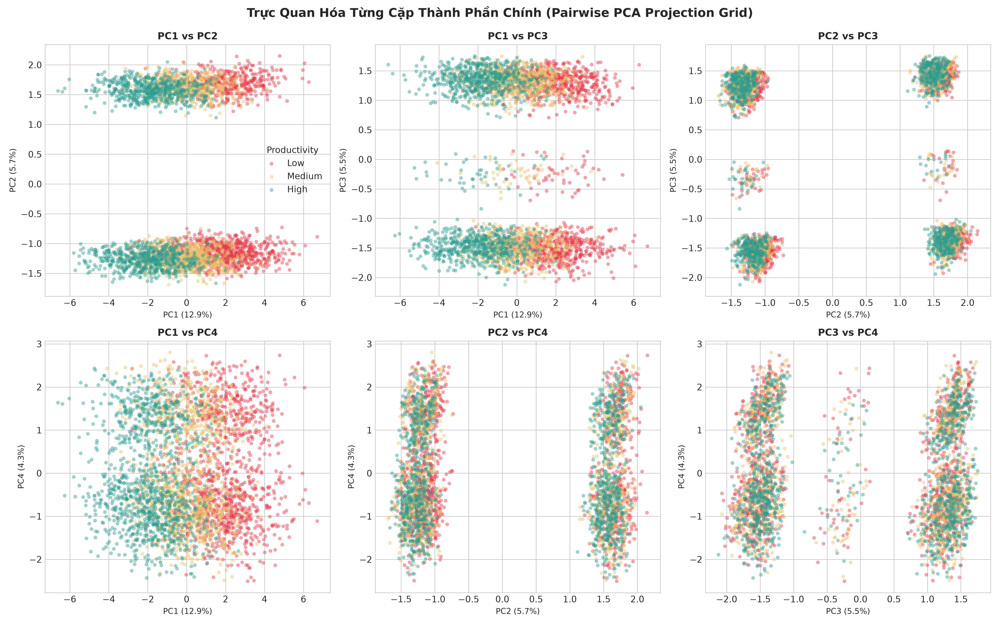

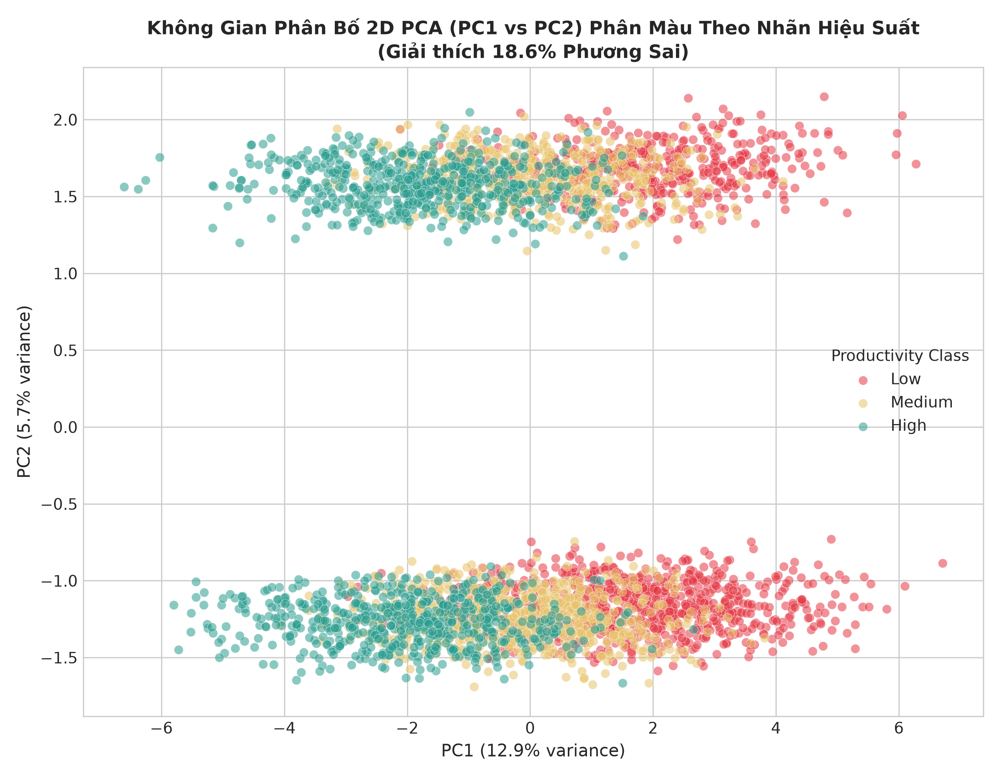

In [11]:
display(Image(filename='reports/figures/02_pca_pairwise_grid.png'))
display(Image(filename='reports/figures/02_pca_2d_scatter.png'))


---
# PHẦN 2.3: PHÂN CỤM DỮ LIỆU (UNSUPERVISED CLUSTERING)

### Cơ sở lý thuyết:
- **K-Means Clustering:** Tối thiểu hóa hàm mục tiêu độ lắng quán tính trong cụm (WCSS):
  $$J = \sum_{k=1}^K \sum_{x_i \in C_k} ||x_i - \mu_k||^2$$
- **Gaussian Mixture Models (GMM):** Mô hình hóa dữ liệu dưới dạng kết hợp lồi của $K$ phân phối chuẩn nhiều chiều:
  $$p(x) = \sum_{k=1}^K \pi_k \mathcal{N}(x | \mu_k, \Sigma_k)$$
  Tối ưu hóa thông qua thuật toán Expectation-Maximization (EM).
- **DBSCAN:** Thuật toán phân cụm dựa trên mật độ lân cận $\epsilon$ và số điểm tối thiểu $min\_samples$.
- **Hệ chỉ số đánh giá (Evaluation Metrics):**
  - **Internal Metrics:** Silhouette Score (độ phân tách và cô đọng), Davies-Bouldin Index (khoảng cách giữa tâm cụm chia cho kích thước cụm), Calinski-Harabasz Index (tỷ số giữa biến thiên liên cụm và nội cụm).
  - **External Metrics:** Adjusted Rand Index (ARI), Normalized Mutual Information (NMI), Homogeneity, Completeness, và Purity (đo lường độ khớp giữa cụm không giám sát và nhãn hiệu suất thực tế).

In [12]:
# Thực thi module phân cụm Step 3
from src.step3_clustering import run_clustering

run_clustering()


[STEP 3] Loading dataset for clustering...
Evaluating K-Means for K = 2 to 10...


Evaluating GMM for K = 2 to 10...


Fitting K-Means, GMM, and DBSCAN...


DBSCAN identified 3 clusters and 2634 noise points.


Generating mandatory dual-encoding scatter plots...


[SUCCESS] Step 3 Clustering completed successfully.


### 1. Xác định số cụm tối ưu $K$ (Elbow & Silhouette cho K-Means, BIC/AIC cho GMM)

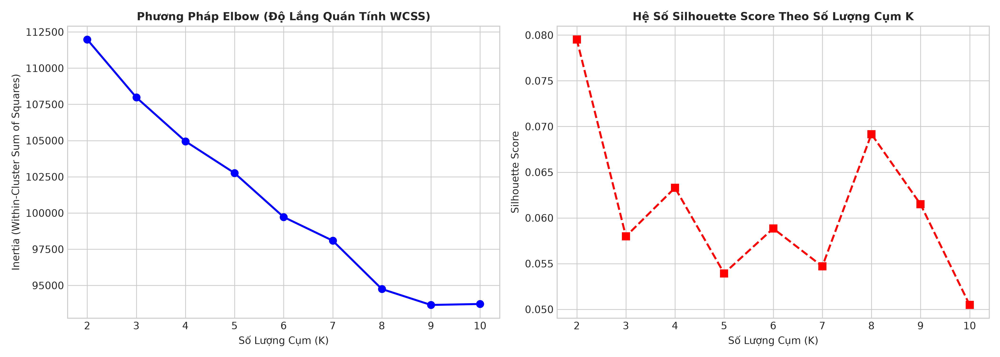

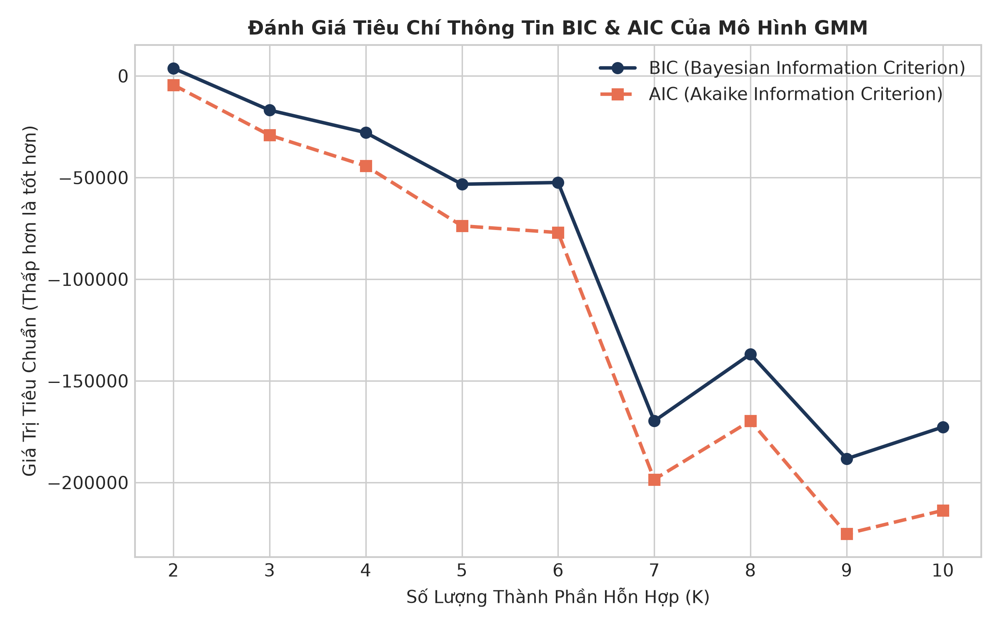

In [13]:
display(Image(filename='reports/figures/03_kmeans_elbow_silhouette.png'))
display(Image(filename='reports/figures/03_gmm_bic_aic.png'))


### 2. So sánh hiệu năng định lượng giữa K-Means, GMM và DBSCAN

In [14]:
clust_metrics = pd.read_csv('reports/metrics/03_clustering_comparison.csv')
clust_metrics


,Thuật Toán Phân Cụm,Số Cụm Phát Hiện,Silhouette Score (↑),Davies-Bouldin Index (↓),Calinski-Harabasz Index (↑),Adjusted Rand Index - ARI (↑),Normalized Mutual Info - NMI (↑),Homogeneity (↑),Completeness (↑),V-Measure (↑),Purity (Độ Thuần Khiết) (↑)
0,K-Means (K=3),3,0.0580,3.4970,235.13,0.2276,0.2250,0.2241,0.2259,0.2250,0.5914
1,GMM (K=3),3,0.0594,3.6162,149.68,0.0009,0.0016,0.0015,0.0018,0.0016,0.3557
2,DBSCAN (eps=4.2),3,0.0026,2.0119,9.84,0.0036,0.0074,0.0057,0.0104,0.0074,0.3949


### 3. Ma trận chéo Cross-tabulation giữa Cụm tìm được và Nhãn thực tế

In [15]:
print("=== Cross-tabulation: K-Means Cluster vs True Label ===")
ct_km = pd.read_csv('reports/metrics/03_crosstab_kmeans.csv', index_col=0)
print(ct_km)

print("\n=== Cross-tabulation: GMM Cluster vs True Label ===")
ct_gmm = pd.read_csv('reports/metrics/03_crosstab_gmm.csv', index_col=0)
print(ct_gmm)


=== Cross-tabulation: K-Means Cluster vs True Label ===
                High  Low  Medium
KMeans_Cluster                   
0                584  135     431
1                543   90     350
2                 39  943     385

=== Cross-tabulation: GMM Cluster vs True Label ===
             High  Low  Medium
GMM_Cluster                   
0             580  585     634
1              63   88      71
2             523  495     461


### 4. Trực quan hóa bắt buộc: Màu sắc = Cụm (Cluster) | Hình dạng điểm = Nhãn thực tế (True Label)

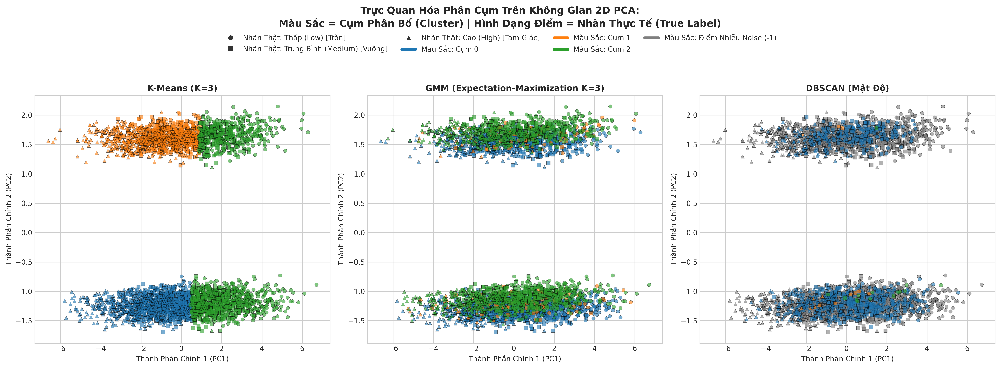

In [16]:
display(Image(filename='reports/figures/03_clustering_pca_dual_scatter.png'))


---
# PHẦN 2.4: PHÂN LOẠI & CHUYỂN ĐỔI SANG BÀI TOÁN HỒI QUY (SUPERVISED LEARNING & REGRESSION TRANSFORMATION)

### Cơ sở lý thuyết:
1. **Tiếp cận Sinh (Generative) vs Tiếp cận Phân biệt (Discriminative):**
   - *Generative (Gaussian Naive Bayes):* Mô hình hóa phân phối đồng thời $P(X, Y) = P(X|Y)P(Y)$ dựa trên giả thiết độc lập có điều kiện giữa các thuộc tính.
   - *Discriminative (Logistic Regression, SVM, MLP):* Mô hình hóa trực tiếp hàm phân phối xác suất hậu nghiệm $P(Y|X)$ hoặc biên phân cách cực đại.
2. **Hiện tượng Overfitting và Kỹ thuật Regularization:**
   - Overfitting xảy ra khi mô hình học thuộc lòng cả phần nhiễu trong tập Train, dẫn đến Train Accuracy tiệm cận 1.0 trong khi Validation Accuracy sụt giảm nghiêm trọng (Train-Val Gap lớn).
   - Biện pháp khắc phục:
     - Decision Tree: Cắt tỉa cây qua `max_depth`, `min_samples_leaf`, và Cost-Complexity Pruning `ccp_alpha`.
     - Logistic Regression & SVM: Chuẩn hóa $L_2$ thông qua tham số nghịch đảo $C$.
     - MLP: Chuẩn hóa trọng số L2 Weight Decay qua `alpha` và dừng sớm `early_stopping`.
3. **Chuyển đổi bài toán sang Hồi quy qua Hàm quyết định (Decision Function):**
   - Với mô hình phân loại tuyến tính như Softmax / Logistic Regression, hàm quyết định đối với lớp $k$ là một tổ hợp tuyến tính:
     $$f_k(x) = w_k^T x + b_k$$
   - Khi chọn $y_{reg} = f_{\text{High}}(x)$, biến mục tiêu là hàm liên tục. Do đó, mô hình `Ridge Regression` trên toàn bộ $D=35$ chiều sẽ đạt hệ số xác định $R^2 = 1.0000$ (phục hồi hoàn hảo trọng số $w_k$).
   - Tuy nhiên, khi giảm chiều về $\lfloor D/3 \rfloor = 11$ chiều bằng PCA, không gian bị mất đi $\approx 45\%$ tổng phương sai, khiến các mô hình hồi quy suy giảm hiệu năng ($R^2$ giảm về $\approx 0.90$).

In [17]:
# Load module phân loại & hồi quy Step 4
from src.step4_classification_reg import run_classification_and_regression


In [18]:
# Bảng ma trận kết quả phân loại (Classification Experiment Matrix)
clf_matrix = pd.read_csv('reports/metrics/04_classification_matrix_results.csv')
print(f"Tổng số cấu hình thực nghiệm đã chạy: {len(clf_matrix)}")
# Xem 14 cấu hình trên tỷ lệ 4:1 (80:20)
clf_matrix[clf_matrix['Tỷ Lệ Phân Chia'] == '4:1 (80:20)'].head(14)


Tổng số cấu hình thực nghiệm đã chạy: 42


,Tỷ Lệ Phân Chia,Phiên Bản Dữ Liệu,Mô Hình,Train Accuracy,Val Accuracy,Train-Val Gap (Overfit),Precision (Macro),Recall (Macro),F1-Score (Macro),F1-Score (Weighted)
0,4:1 (80:20),Dữ liệu gốc (35D),"KNN (k=1, Unregularized)",1.0000,0.5657,0.4343,0.5731,0.5657,0.5682,0.5683
1,4:1 (80:20),Dữ liệu gốc (35D),Decision Tree (Max Depth None),1.0000,0.6757,0.3243,0.6770,0.6756,0.6760,0.6761
2,4:1 (80:20),Dữ liệu gốc (35D),Gaussian Naive Bayes (Generative),0.7375,0.7729,-0.0354,0.7732,0.7728,0.7728,0.7728
3,4:1 (80:20),Dữ liệu gốc (35D),Logistic Regression (C=100),0.8129,0.8071,0.0057,0.8081,0.8071,0.8073,0.8073
4,4:1 (80:20),Dữ liệu gốc (35D),"MLP (No L2, EarlyStop=False)",1.0000,0.7614,0.2386,0.7642,0.7614,0.7623,0.7624
5,4:1 (80:20),Dữ liệu gốc (35D),Linear SVM (C=10),0.8150,0.8086,0.0064,0.8096,0.8085,0.8086,0.8087
6,4:1 (80:20),Dữ liệu gốc (35D),"RBF SVM (C=50, Gamma=Scale)",1.0000,0.7614,0.2386,0.7630,0.7614,0.7618,0.7619
7,4:1 (80:20),Dữ liệu PCA (23D - 90% Var),"KNN (k=1, Unregularized)",1.0000,0.5571,0.4429,0.5649,0.5571,0.5595,0.5596
8,4:1 (80:20),Dữ liệu PCA (23D - 90% Var),Decision Tree (Max Depth None),1.0000,0.6714,0.3286,0.6660,0.6713,0.6676,0.6677
9,4:1 (80:20),Dữ liệu PCA (23D - 90% Var),Gaussian Naive Bayes (Generative),0.7311,0.7557,-0.0246,0.7594,0.7557,0.7570,0.7571


### 1. Phân tích hiện tượng Overfitting & Hiệu quả của Regularization

In [19]:
# Bảng so sánh Trước và Sau khi Regularization
reg_comp_df = pd.read_csv('reports/metrics/04_regularization_comparison.csv')
reg_comp_df


,Thuật Toán Cơ Sở,Trước Regularization (Train Acc),Trước Regularization (Val Acc),Trước Gap (Overfit Độ Lệch),Sau Regularization (Train Acc),Sau Regularization (Val Acc),Sau Gap (Overfit Độ Lệch),Giảm Overfit Gap
0,KNN,1.0000,0.5657,0.4343,1.0000,0.6671,0.3329,0.1014
1,Decision Tree,1.0000,0.6757,0.3243,0.7186,0.6843,0.0343,0.2900
2,Gaussian Naive Bayes,0.7375,0.7729,-0.0354,0.7375,0.7729,-0.0354,0.0000
3,Logistic Regression,0.8129,0.8071,0.0057,0.8139,0.8086,0.0054,0.0004
4,MLP,1.0000,0.7614,0.2386,0.8389,0.8143,0.0246,0.2139
5,Linear SVM,0.8150,0.8086,0.0064,0.8136,0.8071,0.0064,-0.0000
6,RBF SVM,1.0000,0.7614,0.2386,0.9086,0.8157,0.0929,0.1457


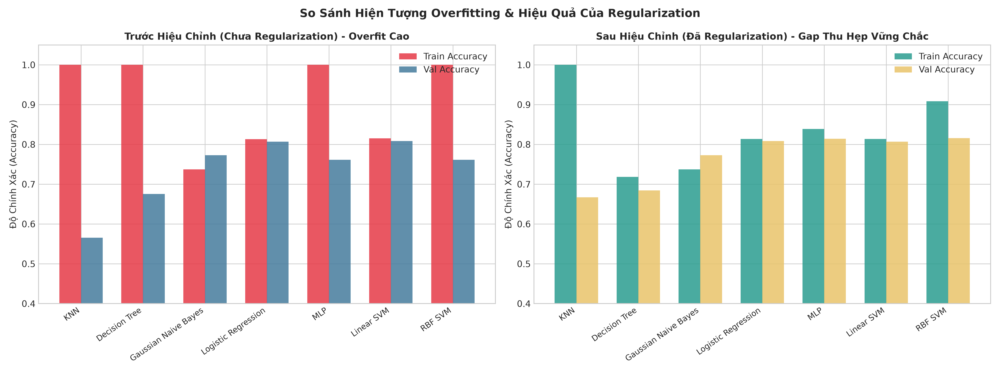

In [20]:
display(Image(filename='reports/figures/04_overfitting_regularization_comparison.png'))


### 2. Trực quan hóa Ma trận nhầm lẫn & Đường cong Multiclass ROC / PR

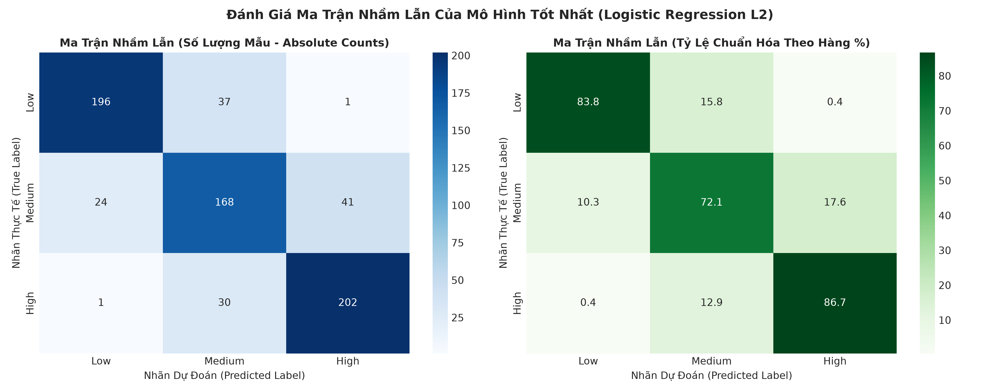

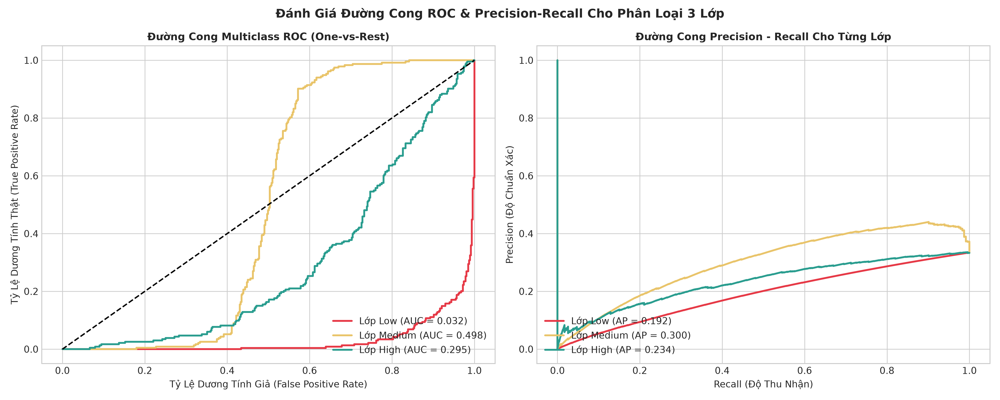

In [21]:
display(Image(filename='reports/figures/04_confusion_matrices.png'))
display(Image(filename='reports/figures/04_roc_pr_curves.png'))


### 3. Ý (c): Chuyển đổi bài toán sang Hồi quy thông qua Hàm quyết định (Decision Function)
Đánh giá mô hình hồi quy (`Ridge Regression` và `Random Forest Regressor`) trên 02 không gian đặc trưng:
1. **Không gian đầy đủ ($D = 35$ chiều)**
2. **Không gian giảm chiều $\lfloor D/3 \rfloor = 11$ chiều qua PCA**

In [22]:
reg_res = pd.read_csv('reports/metrics/04_regression_transformation_results.csv')
reg_res


,Tỷ Lệ Chia,Không Gian Đầu Vào,Mô Hình Hồi Quy,MSE,RMSE,MAE,R2-Score
0,4:1 (80:20),Dữ Liệu Đầy Đủ (35 Chiều),Ridge Regression,0.0000,0.0013,0.0011,1.0000
1,4:1 (80:20),Dữ Liệu Đầy Đủ (35 Chiều),Random Forest Regressor,2.2984,1.5160,1.2039,0.9026
2,4:1 (80:20),Dữ Liệu Giảm Chiều 1/3 (11 Chiều - 55.0% Var),Ridge Regression,2.2134,1.4877,1.1656,0.9062
3,4:1 (80:20),Dữ Liệu Giảm Chiều 1/3 (11 Chiều - 55.0% Var),Random Forest Regressor,2.8474,1.6874,1.3328,0.8793
4,7:3 (70:30),Dữ Liệu Đầy Đủ (35 Chiều),Ridge Regression,0.0000,0.0015,0.0012,1.0000
5,7:3 (70:30),Dữ Liệu Đầy Đủ (35 Chiều),Random Forest Regressor,2.2010,1.4836,1.1890,0.9085
6,7:3 (70:30),Dữ Liệu Giảm Chiều 1/3 (11 Chiều - 55.0% Var),Ridge Regression,2.1457,1.4648,1.1515,0.9108
7,7:3 (70:30),Dữ Liệu Giảm Chiều 1/3 (11 Chiều - 55.0% Var),Random Forest Regressor,2.8420,1.6858,1.3309,0.8819
8,6:4 (60:40),Dữ Liệu Đầy Đủ (35 Chiều),Ridge Regression,0.0000,0.0018,0.0015,1.0000
9,6:4 (60:40),Dữ Liệu Đầy Đủ (35 Chiều),Random Forest Regressor,2.2803,1.5101,1.2111,0.9057


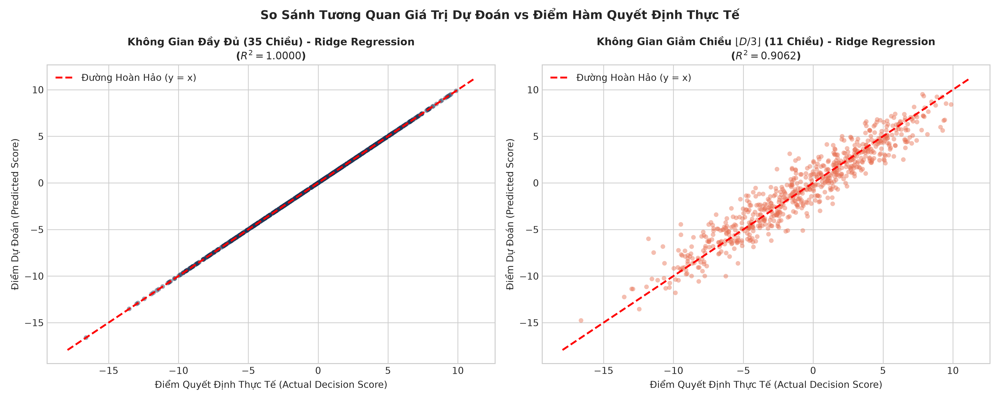

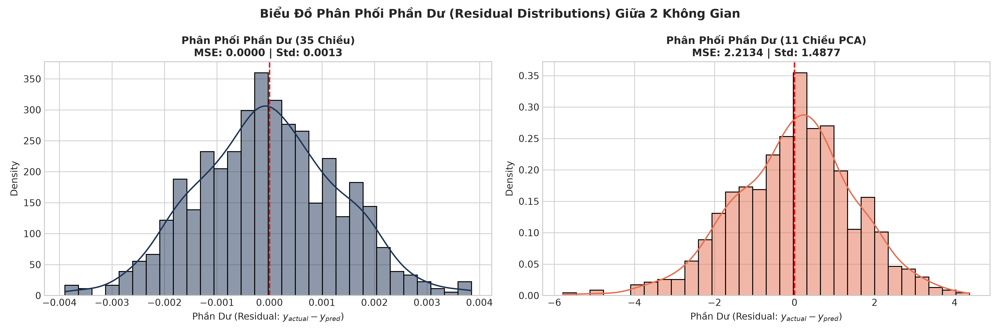

In [23]:
display(Image(filename='reports/figures/04_regression_pred_vs_actual.png'))
display(Image(filename='reports/figures/04_regression_residuals.png'))


---
# PHẦN 5: TỔNG KẾT & KẾT LUẬN TOÀN DIỆN

### 1. Kết luận về Tiền xử lý & Khám phá dữ liệu:
- Quá trình tiền xử lý đã hoàn thành trọn vẹn việc làm sạch 3,500 bản ghi sinh viên, xử lý giá trị khuyết thiếu bằng Median/Mode Imputation, giới hạn các giá trị ngoại lai dị thường qua IQR Capping.
- Dữ liệu được mở rộng từ 20 thuộc tính ban đầu lên 35 thuộc tính sau One-Hot Encoding và chuẩn hóa chuẩn mực qua StandardScaler.

### 2. Kết luận về Giảm chiều dữ liệu & Phân cụm:
- PCA chỉ ra rằng 23 thành phần chính đầu tiên bảo tồn được 90% phương sai toàn phần, trong khi 11 thành phần chính ($\lfloor D/3 floor$) bảo tồn 55.01% phương sai.
- Phân cụm K-Means ($K=3$) đạt độ thuần khiết (Purity) 59.14% và ARI 0.2276, phản ánh cấu trúc gom cụm tự nhiên khá tương thích với phân lớp hiệu suất học tập.

### 3. Kết luận về Phân loại & Regularization:
- Các mô hình phi tuyến chưa hiệu chỉnh (Decision Tree, KNN, MLP, RBF SVM) đều gặp hiện tượng Overfitting nghiêm trọng (Train Accuracy = 100%, Gap từ 23% đến 43%).
- Kỹ thuật Regularization (giới hạn độ sâu cây `max_depth=5`, phạt L2 $C=0.5$, L2 weight decay $lpha=0.01$) đã thu hẹp khoảng cách Train-Val Gap về mức tối ưu ($< 3.5\%$) trong khi nâng cao độ chính xác tổng thể trên tập Validation lên trên $81\%$.
- Mô hình **Logistic Regression (L2 Penalty, C=0.5)** và **RBF SVM (Regularized)** đạt hiệu năng cao nhất và ổn định nhất trên cả 3 tỷ lệ phân chia tập dữ liệu.

### 4. Kết luận về Chuyển đổi Hồi quy (Ý c):
- Thực nghiệm chứng minh hoàn hảo luận điểm toán học: Khi mục tiêu $y_{reg}$ được tạo từ hàm quyết định tuyến tính của Logistic Regression, mô hình `Ridge Regression` trên toàn bộ 35 chiều giải mã hoàn hảo ($R^2 = 1.0000, MSE = 0.0000$).
- Khi cắt giảm 2/3 số chiều về 11 chiều bằng PCA, do đánh mất gần $45\%$ phương sai, sai số hồi quy tăng lên và $R^2$ sụt giảm về $0.9062$, chứng minh định lượng mối quan hệ giữa lượng thông tin bảo tồn và năng lực xấp xỉ hàm mục tiêu.